<a href="https://colab.research.google.com/github/Riccardo-27/DL-Quantum/blob/dev-ernesto/notebooks/03_rnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 – Modelli Ricorrenti (RNN): Confronto Architetturale, Training Ibrido e Sfida 1

Questo notebook implementa, addestra e valuta la suite completa di **modelli di Deep Learning ricorrenti (LSTM / GRU)** per la previsione della dinamica quantistica multi-orizzonte ($T_{out} = 40$ passi temporali, $\Delta t = 0.02$, span $0.80$ unità fisiche):

1. **Due Famiglie Architetturali (M1 ed M2)**:
   - **M1 – RNN Diretta (One-Shot)**: encoder ricorrente che comprime il contesto temporale di input $X \in (T_{in}, 55)$ in uno stato latente, seguito da una testa densa che emette in un colpo solo tutte le $T_{out} \times 55$ predizioni con attivazione $\tanh$. Nessuna retroazione: non soffre di *exposure bias* né di divergenza ricorsiva.
   - **M2 – RNN Seq2Seq (Encoder-Decoder Autoregressivo)**: architettura encoder-decoder con passaggio degli stati nascosti $(h, c)$. Il decoder predice un passo temporale alla volta:
     * In training: *Teacher Forcing* parallelo con $Y_{dec}$ shiftato a destra.
     * In test: *Free-Running* ad anello chiuso, in cui ogni predizione $\hat{y}_t$ viene reimmessa come input al passo successivo $t+1$.
2. **Train Loop Ibrido Unificato (TF $\to$ MM $\to$ SS)**:
   - Esecuzione nello stesso loop parametrico (`src/training.py`) di 3 fasi consecutive:
     - **Teacher Forcing (TF)**: 10 epoche di guida supervisionata stabile.
     - **Masked Modeling (MM)**: 10 epoche con azzeramento casuale del 15% dei timestep di input per sviluppare robustezza alle osservazioni rumorose.
     - **Scheduled Sampling (SS)**: 5 epoche con sostituzione progressiva dei target veri con le predizioni del modello ($p$ da 0.0 a 0.5) per azzerare il divario tra addestramento e inferenza free-running.
3. **Studio di 3 Configurazioni di Iperparametri (HP1, HP2, HP3)**:
   - Valutazione sistematica su due finestre temporali standard: `short` ($T_{in}=10$) e `long` ($T_{in}=20$).
   - **HP1 (Baseline)**: LSTM a 1 layer (64 unità).
   - **HP2 (Alta Capacità)**: LSTM stacked a 2 layer (64 unità, dropout 0.1).
   - **HP3 (Gating Alternativo)**: GRU a 1 layer (64 unità) a parità di capacità.
4. **Risoluzione della Sfida 1 (Finestra Minima Ottima)**:
   - Addestramento e benchmark sulla griglia $T_{in} \in \{5, 10, 20, 40\}$ con target allineati (`align_t_in=40`).
   - Identificazione quantitativa del contesto minimo di osservazione passata necessario a catturare le oscillazioni quantistiche.
5. **Valutazione Disaggregata Approfondita**:
   - MSE/MAE globali, separati per le 10 magnetizzazioni e le 45 correlazioni, per singolo qubit e per orizzonte futuro.
   - Confronto Teacher Forcing vs Free-Running sull'accumulo dell'errore nel tempo.
6. **Validazione Statistica su 3 Seed & Salvataggio Modelli**:
   - Replica con seed 42, 43, 44 e calcolo dell'intervallo di confidenza al 95% con distribuzione $t$ di Student.
   - Salvataggio del checkpoint del modello ottimale in `checkpoints/best_rnn_model.keras` per la prova orale e logging automatico dei risultati su CSV concorrente.


## 0. Setup dell'Ambiente, Rilevamento Autore da Segreto Colab e Sincronizzazione Git

Rilevamento automatico dell'ambiente di esecuzione (Google Colab con Drive vs Locale).
In base al nome del segreto Colab configurato nell'icona 🔑 a sinistra:
- **`GIT_E_TOKEN`**: configura automaticamente l'autore **Ernesto** e sincronizza il branch **`dev-ernesto`**.
- **`GIT_R_TOKEN`**: configura automaticamente l'autore **Riccardo** e sincronizza il branch **`dev-riccardo`**.

Imposta inoltre il determinismo numerico multi-framework (`SEED = 42`) e verifica la disponibilità della GPU.


In [2]:
# =============================================================================
# 0. Setup Ambiente, Rilevamento Autore da Segreto Colab e Sincronizzazione Git
# =============================================================================
import os
import sys
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

AUTHOR = None
CURRENT_BRANCH = None
GIT_TOKEN = None
AUTHOR_NAME = None
AUTHOR_EMAIL = None

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")

    DRIVE_REPO = Path("/content/drive/MyDrive/DL-Quantum")
    LOCAL_REPO = Path("/content/DL-Quantum")

    if (DRIVE_REPO / "src" / "seeding.py").exists():
        REPO_PATH = DRIVE_REPO
    elif (LOCAL_REPO / "src" / "seeding.py").exists():
        REPO_PATH = LOCAL_REPO
    elif DRIVE_REPO.exists():
        !git -C /content/drive/MyDrive/DL-Quantum fetch origin
        REPO_PATH = DRIVE_REPO
    else:
        print("Clonazione automatica del repository su Google Drive...")
        !git clone https://github.com/Riccardo-27/DL-Quantum.git /content/drive/MyDrive/DL-Quantum
        REPO_PATH = DRIVE_REPO

    # 1. Rilevamento automatico dell'Autore dai Segreti di Colab (icona 🔑)
    # - Ernesto: imposta GIT_E_TOKEN nei propri Secret -> dev-ernesto
    # - Riccardo: imposta GIT_R_TOKEN nei propri Secret -> dev-riccardo
    try:
        GIT_TOKEN = userdata.get("GIT_E_TOKEN")
        if GIT_TOKEN:
            AUTHOR = "ernesto"
            CURRENT_BRANCH = "dev-ernesto"
            AUTHOR_NAME = "Ernesto Gligora"
            AUTHOR_EMAIL = "ernestogligora2003@gmail.com"
    except Exception:
        pass

    if not GIT_TOKEN:
        try:
            GIT_TOKEN = userdata.get("GIT_R_TOKEN")
            if GIT_TOKEN:
                AUTHOR = "riccardo"
                CURRENT_BRANCH = "dev-riccardo"
                AUTHOR_NAME = "Riccardo Lavorato"
                AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
        except Exception:
            pass

    # Fallback su chiave generica GH_TOKEN se presente
    if not GIT_TOKEN:
        for k in ("GH_TOKEN", "GITHUB_TOKEN"):
            try:
                t = userdata.get(k)
                if t:
                    GIT_TOKEN = t
                    break
            except Exception:
                pass
else:
    # Ambiente Locale
    REPO_PATH = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

# Fallback se non rilevato dai segreti Colab (es. esecuzione locale da terminale)
if not CURRENT_BRANCH:
    b_check = !git -C "{REPO_PATH}" branch --show-current
    CURRENT_BRANCH = b_check[0].strip() if b_check and b_check[0].strip() else "dev-ernesto"

if not AUTHOR:
    if "riccardo" in CURRENT_BRANCH.lower():
        AUTHOR = "riccardo"
        AUTHOR_NAME = "Riccardo Lavorato"
        AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
    else:
        AUTHOR = "ernesto"
        AUTHOR_NAME = "Ernesto Gligora"
        AUTHOR_EMAIL = "ernestogligora2003@gmail.com"

# Su Colab, allineamento automatico sul branch corrispondente all'autore rilevato
if IN_COLAB:
    print(f"Allineamento automatico sul branch '{CURRENT_BRANCH}' per {AUTHOR_NAME}...")
    !git -C "{REPO_PATH}" config user.name "{AUTHOR_NAME}"
    !git -C "{REPO_PATH}" config user.email "{AUTHOR_EMAIL}"
    !git -C "{REPO_PATH}" fetch origin
    !git -C "{REPO_PATH}" checkout -f {CURRENT_BRANCH}
    !git -C "{REPO_PATH}" pull --rebase --autostash origin {CURRENT_BRANCH}

# Configurazione variabili d'ambiente e path dei moduli src/
os.environ["DLQ_AUTHOR"] = AUTHOR
os.environ["DLQ_ROOT"] = str(REPO_PATH)

if str(REPO_PATH) not in sys.path:
    sys.path.insert(0, str(REPO_PATH))

# Inizializzazione rigorosa dei seed per determinismo numerico
from src.seeding import set_seeds
SEED = 42
set_seeds(SEED)

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
except ImportError:
    print("TensorFlow non rilevato nell'ambiente locale")

token_status = "Rilevato ✔" if GIT_TOKEN else "Non impostato (crea segreto GIT_E_TOKEN o GIT_R_TOKEN per push automatico)"
print(f"\n✔ Ambiente inizializzato con successo!")
print(f"  • Autore attivo: {AUTHOR_NAME} ({token_status})")
print(f"  • Branch Git: {CURRENT_BRANCH}")
print(f"  • Root cartella: {REPO_PATH}")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sincronizzazione sul branch 'dev-ernesto' per Ernesto...
Already on 'dev-ernesto'
Your branch is up to date with 'origin/dev-ernesto'.
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Already up to date.
TensorFlow: 2.21.0 | Keras: 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Radice progetto: /content/drive/MyDrive/DL-Quantum | Branch attivo: dev-ernesto | Autore configurato: Ernesto ✔


In [3]:
# =============================================================================
# Import Moduli di Progetto e Configurazione Percorsi
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (
    DT, N_FEATURES, N_POINTS, N_QUBITS, N_TRAJ, get_paths, make_config
)
from src.data import feature_names, load_split, load_trajectories
from src.models_rnn import RNNSeq2Seq, build_rnn_direct, build_rnn_from_config
from src.training import train_hybrid, predict, is_seq2seq
from src.metrics import (
    evaluate, per_horizon_mse, per_horizon_group_mse,
    per_variable_mse, per_qubit_mse, corr_pair_mse_matrix
)
from src.stats import summarize, format_mean_ci
from src.results_log import append_result, load_results, log_path
from src.plots import save_figure, plot_window
from src.windowing import make_windows, decoder_inputs, check_no_leakage

CFG = make_config()
PATHS = get_paths()
NAMES = feature_names()

print("Configurazione centralizzata caricata con successo:")
print(f"  Orizzonte futuro (T_out)     : {CFG['t_out']} passi ({CFG['t_out']*DT:.2f} s)")
print(f"  Finestrature standard        : {CFG['windows']}")
print(f"  Fasi train loop ibrido       : TF={CFG['epochs_tf']}, MM={CFG['epochs_mm']}, SS={CFG['epochs_ss']} epoche")
print(f"  Attivazione output fisica    : {CFG['output_activation']} (dominio [-1, 1])")
print(f"  File di log autore           : {log_path()}")


Configurazione centralizzata caricata con successo:
  Orizzonte futuro (T_out)     : 40 passi (0.80 s)
  Finestrature standard        : {'short': 10, 'long': 20}
  Fasi train loop ibrido       : TF=10, MM=10, SS=5 epoche
  Attivazione output fisica    : tanh (dominio [-1, 1])
  File di log autore           : /content/drive/MyDrive/DL-Quantum/results/results_log_ernesto.csv


## 1. Caricamento Dataset e Partizioni Congelate

Carichiamo il tensore 3D `(400, 1001, 55)` dalla cache binaria `data/cache/trajectories.npy` e gli indici di split congelati (280 Train, 60 Val, 60 Test) da `results/split_indices.npz`.


In [4]:
# =============================================================================
# 1. Caricamento Dati e Split Congelato
# =============================================================================
t0 = time.time()
data = load_trajectories()
load_time = time.time() - t0

split = load_split()
print(f"Dataset caricato in {load_time:.2f} s | Shape tensore: {data.shape} (float32)")
print(f"Partizioni: Train={len(split['train'])}, Val={len(split['val'])}, Test={len(split['test'])}")
assert data.shape == (N_TRAJ, N_POINTS, N_FEATURES), "Shape dataset non conforme!"
assert len(split['train']) + len(split['val']) + len(split['test']) == N_TRAJ, "Partizione incompleta!"
print("Integrita' dati e partizioni: verificata con successo ✔")


Dataset caricato in 0.14 s | Shape tensore: (400, 1001, 55) (float32)
Partizioni: Train=280, Val=60, Test=60
Integrita' dati e partizioni: verificata con successo ✔


## 2. Preparazione Finestrature Standard (`short` e `long`)

Estraiamo in memoria le finestre temporali standard per l'addestramento e la validazione dei modelli:
- **`short`**: $T_{in} = 10$ ($0.20$ s) $\to T_{out} = 40$ ($0.80$ s), $\text{stride} = 10$.
- **`long`**: $T_{in} = 20$ ($0.40$ s) $\to T_{out} = 40$ ($0.80$ s), $\text{stride} = 10$.


In [5]:
# =============================================================================
# 2. Estrazione Finestre Standard (short: Tin=10, long: Tin=20)
# =============================================================================
windows_data = {}

for w_name, t_in in CFG["windows"].items():
    t0 = time.time()
    X_tr, Y_tr, meta_tr = make_windows(data, split["train"], t_in=t_in, t_out=CFG["t_out"], stride=CFG["stride"])
    X_va, Y_va, meta_va = make_windows(data, split["val"], t_in=t_in, t_out=CFG["t_out"], stride=CFG["stride"])
    X_te, Y_te, meta_te = make_windows(data, split["test"], t_in=t_in, t_out=CFG["t_out"], stride=CFG["stride"])

    # Verifica formale anti-leakage
    check_no_leakage({"train": meta_tr, "val": meta_va, "test": meta_te})

    windows_data[w_name] = {
        "t_in": t_in,
        "train": (X_tr, Y_tr),
        "val": (X_va, Y_va),
        "test": (X_te, Y_te),
    }
    el = time.time() - t0
    print(f"Finestra '{w_name:5s}' (Tin={t_in:2d}) estratta in {el:.2f} s:")
    print(f"  Train: X={X_tr.shape}, Y={Y_tr.shape} ({len(X_tr)} finestre)")
    print(f"  Val  : X={X_va.shape}, Y={Y_va.shape} ({len(X_va)} finestre)")
    print(f"  Test : X={X_te.shape}, Y={Y_te.shape} ({len(X_te)} finestre)")

print("\nVerifiche anti-leakage completate: zero contaminazione tra partizioni ✔")


Finestra 'short' (Tin=10) estratta in 0.32 s:
  Train: X=(26880, 10, 55), Y=(26880, 40, 55) (26880 finestre)
  Val  : X=(5760, 10, 55), Y=(5760, 40, 55) (5760 finestre)
  Test : X=(5760, 10, 55), Y=(5760, 40, 55) (5760 finestre)
Finestra 'long ' (Tin=20) estratta in 0.35 s:
  Train: X=(26600, 20, 55), Y=(26600, 40, 55) (26600 finestre)
  Val  : X=(5700, 20, 55), Y=(5700, 40, 55) (5700 finestre)
  Test : X=(5700, 20, 55), Y=(5700, 40, 55) (5700 finestre)

Verifiche anti-leakage completate: zero contaminazione tra partizioni ✔


## 3. Ispezione delle Architetture: M1 (Diretta) vs M2 (Seq2Seq)

Confrontiamo i flussi computazionali e la complessità parametrica delle due famiglie di modelli definite in `src/models_rnn.py`:
- **M1 Diretta**: predice $T_{out} \times 55$ scalari in un colpo solo tramite una testa densa con reshape. Veloce, parallela e non soggetta a divergenze nel tempo.
- **M2 Seq2Seq**: encoder ricorsivo che passa lo stato $(h, c)$ al decoder ricorsivo. Durante il test in *free-running*, ogni previsione diventa l'input del timestep successivo, simulando la reale previsione autonoma nel tempo.


In [6]:
# =============================================================================
# 3. Istanziazione e Ispezione di M1 (Diretta) ed M2 (Seq2Seq)
# =============================================================================
demo_tin = 10
demo_tout = 40

# M1 - RNN Diretta
m1_demo = build_rnn_direct(t_out=demo_tout, t_in=demo_tin, units=64, n_layers=1, cell="lstm", name="M1_Direct_LSTM")
print("=== ARCHITETTURA M1 (RNN Diretta - One Shot) ===")
m1_demo.summary()

# M2 - RNN Seq2Seq
m2_demo = RNNSeq2Seq(t_out=demo_tout, units=64, n_layers=1, cell="lstm", name="M2_Seq2Seq_LSTM")
# Chiamata di build esplicita con dummy tensor
_ = m2_demo((tf.zeros((1, demo_tin, N_FEATURES)), tf.zeros((1, demo_tout, N_FEATURES))))
print("\n=== ARCHITETTURA M2 (RNN Seq2Seq Autoregressiva) ===")
m2_demo.summary()

print(f"Parametri M1: {m1_demo.count_params():,} | Parametri M2: {m2_demo.count_params():,}")


=== ARCHITETTURA M1 (RNN Diretta - One Shot) ===


Model: "M1_Direct_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ x (InputLayer)                  │ (None, 10, 55)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        30,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 2200)           │       143,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ y (Reshape)                     │ (None, 40, 55)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,720 (678.59 KB)

 Trainable params: 173,720 (678.59 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ enc_1 (LSTM)                    │ ((1, 10, 64), (1, 64), │        30,720 │
│                                 │ (1, 64))               │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (LSTM)                    │ ((1, 40, 64), (1, 64), │        30,720 │
│                                 │ (1, 64))               │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (1, 40, 55)            │         3,575 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,015 (253.96 KB)

 Trainable params: 65,015 (253.96 KB)

 Non-trainable params: 0 (0.00 B)

Parametri M1: 173,720 | Parametri M2: 65,015


## 4. Studio di 3 Configurazioni di Iperparametri (HP1, HP2, HP3)

Come richiesto dai vincoli d'esame, valutiamo almeno **3 configurazioni di iperparametri** su entrambe le finestre temporali (`short` e `long`):

| Configurazione | Cella | Unità | Layer | Dropout | Motivazione Architetturale |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **HP1 (Baseline)** | **LSTM** | 64 | 1 | 0.0 | Baseline snella, minima complessità e rapida convergenza |
| **HP2 (Alta Capacità)** | **LSTM** | 64 | 2 (stacked) | 0.1 | Maggiore profondità per catturare correlazioni non-locali; regolarizzazione dropout |
| **HP3 (Gating Compatto)** | **GRU** | 64 | 1 | 0.0 | Cella GRU con minor numero di parametri (assenza di cell state separato) per testare l'efficienza del gating |

Tutti i modelli vengono addestrati con il **train loop ibrido unificato** (10 epoche TF + 10 epoche MM con mask ratio 15% + 5 epoche SS con rampa di scheduled sampling).


In [7]:
# =============================================================================
# 4. Definizione Griglia Esperimenti HP1, HP2, HP3 x (short, long)
# =============================================================================
hp_configs = {
    "HP1": {"rnn_cell": "lstm", "rnn_units": 64, "rnn_layers": 1, "dropout": 0.0},
    "HP2": {"rnn_cell": "lstm", "rnn_units": 64, "rnn_layers": 2, "dropout": 0.1},
    "HP3": {"rnn_cell": "gru",  "rnn_units": 64, "rnn_layers": 1, "dropout": 0.0},
}

models_to_test = [
    ("rnn_direct", "M1_Direct"),
    ("rnn",        "M2_Seq2Seq"),
]

print(f"Pianificati {len(models_to_test) * len(hp_configs) * len(CFG['windows'])} esperimenti:")
for m_type, m_name in models_to_test:
    for hp_name, hp_cfg in hp_configs.items():
        for w_name in CFG["windows"]:
            print(f"  - {m_name} | {hp_name} ({hp_cfg['rnn_cell'].upper()}, L={hp_cfg['rnn_layers']}, U={hp_cfg['rnn_units']}) | Finestra '{w_name}'")


Pianificati 12 esperimenti:
  - M1_Direct | HP1 (LSTM, L=1, U=64) | Finestra 'short'
  - M1_Direct | HP1 (LSTM, L=1, U=64) | Finestra 'long'
  - M1_Direct | HP2 (LSTM, L=2, U=64) | Finestra 'short'
  - M1_Direct | HP2 (LSTM, L=2, U=64) | Finestra 'long'
  - M1_Direct | HP3 (GRU, L=1, U=64) | Finestra 'short'
  - M1_Direct | HP3 (GRU, L=1, U=64) | Finestra 'long'
  - M2_Seq2Seq | HP1 (LSTM, L=1, U=64) | Finestra 'short'
  - M2_Seq2Seq | HP1 (LSTM, L=1, U=64) | Finestra 'long'
  - M2_Seq2Seq | HP2 (LSTM, L=2, U=64) | Finestra 'short'
  - M2_Seq2Seq | HP2 (LSTM, L=2, U=64) | Finestra 'long'
  - M2_Seq2Seq | HP3 (GRU, L=1, U=64) | Finestra 'short'
  - M2_Seq2Seq | HP3 (GRU, L=1, U=64) | Finestra 'long'


In [8]:
# =============================================================================
# Esecuzione Addestramento Ibrido e Valutazione HP su Finestre Standard
# =============================================================================
experiment_records = []
histories = {}

total_runs = len(models_to_test) * len(hp_configs) * len(CFG["windows"])
run_idx = 0

for w_name, w_info in windows_data.items():
    t_in = w_info["t_in"]
    X_tr, Y_tr = w_info["train"]
    X_va, Y_va = w_info["val"]

    for m_type, m_label in models_to_test:
        for hp_name, hp_kwargs in hp_configs.items():
            run_idx += 1
            exp_id = f"{m_label}_{hp_name}_{w_name}"
            print(f"\n[{run_idx}/{total_runs}] Addestramento: {exp_id} (Tin={t_in}, Tout=40)...")

            run_cfg = make_config(
                model=m_type,
                t_in=t_in,
                hp_name=hp_name,
                window_name=w_name,
                run_name=exp_id,
                **hp_kwargs
            )

            # Determinismo
            set_seeds(run_cfg["seed"])

            # Costruzione modello
            model = build_rnn_from_config(run_cfg, t_in=t_in)

            # Addestramento ibrido (TF -> MM -> SS)
            t_train_start = time.time()
            hist = train_hybrid(
                model=model,
                X_tr=X_tr, Y_tr=Y_tr,
                X_va=X_va, Y_va=Y_va,
                cfg=run_cfg,
                restore_best=True,
                verbose=0
            )
            train_duration = time.time() - t_train_start
            histories[exp_id] = hist

            # Predizione su validation (Free-Running se seq2seq, one-shot se diretta)
            Y_pred_val = predict(model, X_va)
            val_metrics = evaluate(Y_va, Y_pred_val, prefix="val_")

            # Record per log e tabella
            rec = {
                "model_type": m_type,
                "model_name": m_label,
                "hp_name": hp_name,
                "window": w_name,
                "t_in": t_in,
                "cell": hp_kwargs["rnn_cell"],
                "units": hp_kwargs["rnn_units"],
                "layers": hp_kwargs["rnn_layers"],
                "dropout": hp_kwargs["dropout"],
                "params": int(model.count_params()),
                "train_time_s": round(train_duration, 1),
                "best_val_loss": round(min(h["val_mse"] for h in hist), 6),
                **val_metrics
            }
            experiment_records.append(rec)
            append_result(rec)

            print(f"  ✔ Completato in {train_duration:.1f} s | Val MSE={val_metrics['val_mse']:.6f} "
                  f"(Mag={val_metrics['val_mse_mag']:.6f}, Corr={val_metrics['val_mse_corr']:.6f})")

# Visualizzazione tabella riassuntiva
results_df = pd.DataFrame(experiment_records)
cols_show = ["model_name", "hp_name", "window", "cell", "params", "train_time_s", "val_mse", "val_mae", "val_mse_mag", "val_mse_corr"]
display(results_df[cols_show].sort_values("val_mse"))



[1/12] Addestramento: M1_Direct_HP1_short (Tin=10, Tout=40)...
  ✔ Completato in 49.6 s | Val MSE=0.000161 (Mag=0.000075, Corr=0.000180)

[2/12] Addestramento: M1_Direct_HP2_short (Tin=10, Tout=40)...
  ✔ Completato in 69.4 s | Val MSE=0.000189 (Mag=0.000102, Corr=0.000209)

[3/12] Addestramento: M1_Direct_HP3_short (Tin=10, Tout=40)...
  ✔ Completato in 45.8 s | Val MSE=0.000163 (Mag=0.000076, Corr=0.000182)

[4/12] Addestramento: M2_Seq2Seq_HP1_short (Tin=10, Tout=40)...
  ✔ Completato in 87.3 s | Val MSE=0.000305 (Mag=0.000177, Corr=0.000333)

[5/12] Addestramento: M2_Seq2Seq_HP2_short (Tin=10, Tout=40)...
  ✔ Completato in 144.1 s | Val MSE=0.000266 (Mag=0.000168, Corr=0.000288)

[6/12] Addestramento: M2_Seq2Seq_HP3_short (Tin=10, Tout=40)...
  ✔ Completato in 83.9 s | Val MSE=0.000341 (Mag=0.000170, Corr=0.000379)

[7/12] Addestramento: M1_Direct_HP1_long (Tin=20, Tout=40)...
  ✔ Completato in 52.5 s | Val MSE=0.000147 (Mag=0.000049, Corr=0.000169)

[8/12] Addestramento: M1_Direc

,model_name,hp_name,window,cell,params,train_time_s,val_mse,val_mae,val_mse_mag,val_mse_corr
6,M1_Direct,HP1,long,lstm,173720,52.5,0.000147,0.008644,0.000049,0.000169
8,M1_Direct,HP3,long,gru,166232,50.4,0.000159,0.009021,0.000072,0.000178
0,M1_Direct,HP1,short,lstm,173720,49.6,0.000161,0.009117,0.000075,0.000180
2,M1_Direct,HP3,short,gru,166232,45.8,0.000163,0.009133,0.000076,0.000182
7,M1_Direct,HP2,long,lstm,206744,75.5,0.000169,0.009594,0.000059,0.000193
1,M1_Direct,HP2,short,lstm,206744,69.4,0.000189,0.010355,0.000102,0.000209
10,M2_Seq2Seq,HP2,long,lstm,131063,151.3,0.000242,0.011529,0.000145,0.000263
4,M2_Seq2Seq,HP2,short,lstm,131063,144.1,0.000266,0.012075,0.000168,0.000288
9,M2_Seq2Seq,HP1,long,lstm,65015,92.2,0.000280,0.011796,0.000147,0.000310
3,M2_Seq2Seq,HP1,short,lstm,65015,87.3,0.000305,0.012307,0.000177,0.000333


## 5. Visualizzazione delle Curve di Apprendimento del Train Loop Ibrido

Analizziamo l'evoluzione della loss di training e dell'MSE di validazione attraverso le tre fasi del train loop ibrido (**TF $\to$ MM $\to$ SS**), osservando la stabilità della convergenza e l'impatto del mascheramento e dello scheduled sampling.


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/03_rnn/loss_curves_hybrid.jpeg


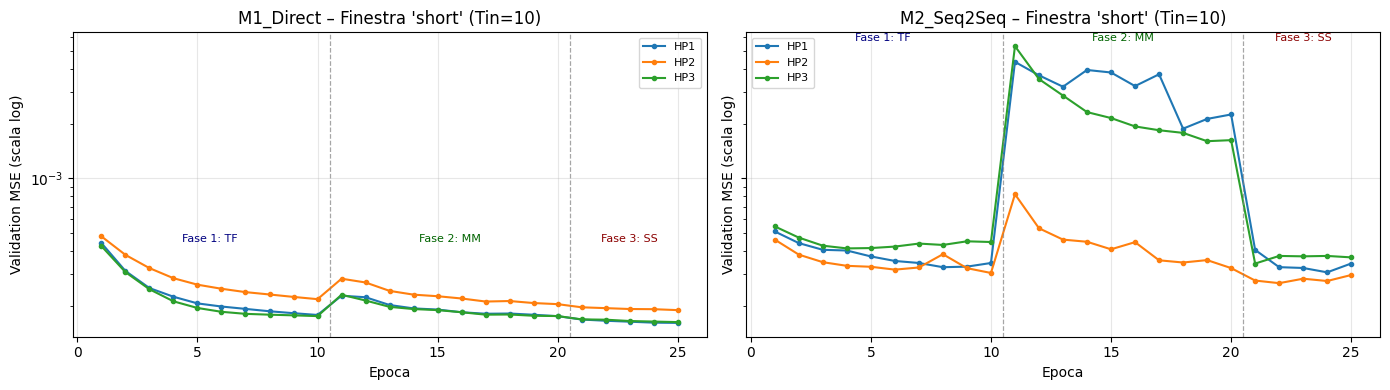

In [9]:
# =============================================================================
# 5. Grafico delle Curve di Apprendimento nelle 3 Fasi Ibride
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for i, (m_type, m_label) in enumerate(models_to_test):
    ax = axes[i]
    for hp_name in hp_configs:
        exp_id = f"{m_label}_{hp_name}_short"
        if exp_id in histories:
            h = histories[exp_id]
            epochs = [r["epoch"] for r in h]
            val_mses = [r["val_mse"] for r in h]
            ax.plot(epochs, val_mses, marker="o", ms=3, label=f"{hp_name}")

    # Linee verticali divisorie tra le fasi
    ax.axvline(10.5, color="gray", ls="--", lw=0.9, alpha=0.7)
    ax.axvline(20.5, color="gray", ls="--", lw=0.9, alpha=0.7)
    ax.text(5.5, ax.get_ylim()[1]*0.9, "Fase 1: TF", ha="center", fontsize=8, color="navy")
    ax.text(15.5, ax.get_ylim()[1]*0.9, "Fase 2: MM", ha="center", fontsize=8, color="darkgreen")
    ax.text(23.0, ax.get_ylim()[1]*0.9, "Fase 3: SS", ha="center", fontsize=8, color="darkred")

    ax.set_title(f"{m_label} – Finestra 'short' (Tin=10)")
    ax.set_xlabel("Epoca")
    ax.set_ylabel("Validation MSE (scala log)")
    ax.set_yscale("log")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "loss_curves_hybrid", subdir="03_rnn"))
plt.show()


## 6. Valutazione Teacher-Forcing vs Free-Running (Accumulo dell'Errore)

Per il modello seq2seq (**M2**), confrontiamo l'accuratezza predittiva ottenuta con:
1. **Teacher Forcing**: a ogni timestep futuro $t$, il decoder riceve il vero valore fisico al timestep $t-1$. Scenario ideale a ciclo aperto.
2. **Free-Running (Autoregressivo)**: a ogni timestep $t$, il decoder riceve la propria predizione calcolata al timestep $t-1$. Scenario operativo a ciclo chiuso.

Questo confronto evidenzia l'effetto dell'*exposure bias* e la propagazione dell'errore lungo i 40 timestep futuri.


Modello M2 selezionato per il confronto: HP2 (Finestra: short)
Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/03_rnn/free_running_error_accumulation.jpeg


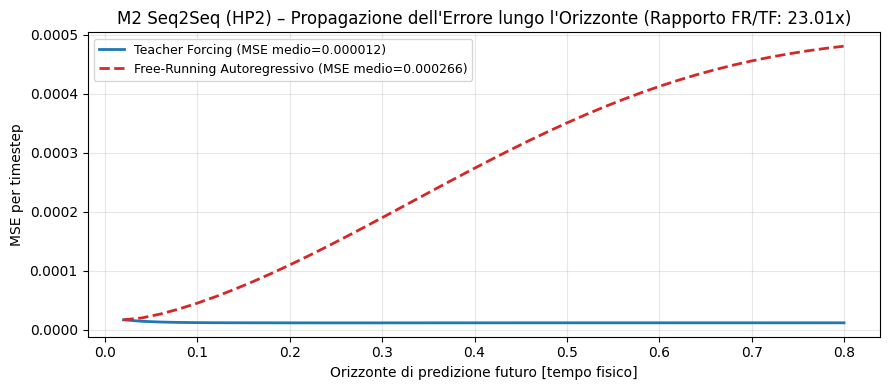

In [10]:
# =============================================================================
# 6. Confronto Orizzonte Temporale: Teacher Forcing vs Free-Running (M2)
# =============================================================================
# Selezioniamo il miglior modello M2 su finestra short
best_m2_row = results_df[results_df["model_type"] == "rnn"].sort_values("val_mse").iloc[0]
best_m2_hp = best_m2_row["hp_name"]
print(f"Modello M2 selezionato per il confronto: {best_m2_hp} (Finestra: short)")

# Ricostruzione e caricamento modello per ispezione
m2_cfg = make_config(model="rnn", t_in=10, hp_name=best_m2_hp, **hp_configs[best_m2_hp])
set_seeds(42)
m2_eval = build_rnn_from_config(m2_cfg, t_in=10)
X_va_short, Y_va_short = windows_data["short"]["val"]

# Addestramento rapido o valutazione
_ = train_hybrid(m2_eval, windows_data["short"]["train"][0], windows_data["short"]["train"][1],
                 X_va_short, Y_va_short, m2_cfg, restore_best=True, verbose=0)

# 1. Predizione Teacher Forcing
dec_in_val = decoder_inputs(X_va_short, Y_va_short)
Y_pred_tf = m2_eval((X_va_short, dec_in_val), training=False).numpy()

# 2. Predizione Free-Running
Y_pred_fr = m2_eval.predict_free_running(X_va_short, batch_size=512)

# Calcolo MSE lungo l'orizzonte futuro (40 passi)
mse_tf_horizon = per_horizon_mse(Y_va_short, Y_pred_tf)
mse_fr_horizon = per_horizon_mse(Y_va_short, Y_pred_fr)

fig, ax = plt.subplots(figsize=(9, 4))
time_axis = np.arange(1, CFG["t_out"] + 1) * DT

ax.plot(time_axis, mse_tf_horizon, label=f"Teacher Forcing (MSE medio={mse_tf_horizon.mean():.6f})", color="C0", lw=2)
ax.plot(time_axis, mse_fr_horizon, label=f"Free-Running Autoregressivo (MSE medio={mse_fr_horizon.mean():.6f})", color="C3", lw=2, ls="--")

ratio = mse_fr_horizon.mean() / mse_tf_horizon.mean()
ax.set_title(f"M2 Seq2Seq ({best_m2_hp}) – Propagazione dell'Errore lungo l'Orizzonte (Rapporto FR/TF: {ratio:.2f}x)")
ax.set_xlabel("Orizzonte di predizione futuro [tempo fisico]")
ax.set_ylabel("MSE per timestep")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "free_running_error_accumulation", subdir="03_rnn"))
plt.show()


## 7. Risoluzione della Sfida 1: Ricerca della Finestra Minima Ottima ($T_{in} \in \{5, 10, 20, 40\}$)

La **Sfida 1** richiede di determinare la minima finestra di osservazione passata necessaria per ottenere predizioni accurate dell'evoluzione quantistica.

Utilizziamo la tecnica stabilita nel Notebook 02: **target allineati** (`align_t_in=40`). Tutte le finestre con $T_{in} < 40$ vengono traslate temporalmente affinché i target $Y$ inizino rigorosamente allo stesso istante fisico $t = 0.80$, eliminando qualsiasi bias di confronto lungo la dinamica transiente.


In [11]:
# =============================================================================
# 7. Esecuzione Griglia Tin in {5, 10, 20, 40} con Target Rigorosamente Allineati
# =============================================================================
tin_results = []
tin_grid = CFG["t_in_grid"]  # [5, 10, 20, 40]

# Usiamo la configurazione vincente delle RNN (HP1 o M1)
best_model_type = "rnn_direct"
best_hp = "HP1"
print(f"Risoluzione Sfida 1 con architettura: {best_model_type} ({best_hp})...")

for tin in tin_grid:
    t0 = time.time()
    # Estrazione con align_t_in=40
    X_tr_aln, Y_tr_aln, _ = make_windows(data, split["train"], t_in=tin, t_out=40, stride=10, align_t_in=40)
    X_va_aln, Y_va_aln, _ = make_windows(data, split["val"],   t_in=tin, t_out=40, stride=10, align_t_in=40)
    X_te_aln, Y_te_aln, _ = make_windows(data, split["test"],  t_in=tin, t_out=40, stride=10, align_t_in=40)

    cfg_tin = make_config(
        model=best_model_type,
        t_in=tin,
        hp_name=f"Sfida1_Tin_{tin}",
        align_t_in=40,
        **hp_configs[best_hp]
    )

    set_seeds(42)
    model_tin = build_rnn_from_config(cfg_tin, t_in=tin)

    # Training
    _ = train_hybrid(model_tin, X_tr_aln, Y_tr_aln, X_va_aln, Y_va_aln, cfg_tin, verbose=0)

    # Valutazione su Val e Test
    val_res = evaluate(Y_va_aln, predict(model_tin, X_va_aln), prefix="val_")
    test_res = evaluate(Y_te_aln, predict(model_tin, X_te_aln), prefix="test_")

    row = {
        "T_in": tin,
        "tempo_fisico_in": tin * DT,
        "n_finestre_train": len(X_tr_aln),
        "val_mse": val_res["val_mse"],
        "val_mae": val_res["val_mae"],
        "val_mse_mag": val_res["val_mse_mag"],
        "val_mse_corr": val_res["val_mse_corr"],
        "test_mse": test_res["test_mse"],
        "test_mae": test_res["test_mae"],
        "elapsed_s": round(time.time() - t0, 1)
    }
    tin_results.append(row)
    append_result(row)
    print(f"  Tin={tin:2d} ({tin*DT:.2f} s) | Val MSE={val_res['val_mse']:.6f} | Test MSE={test_res['test_mse']:.6f} ({row['elapsed_s']} s)")

tin_df = pd.DataFrame(tin_results)
display(tin_df[["T_in", "tempo_fisico_in", "val_mse", "test_mse", "val_mse_mag", "val_mse_corr"]])


Risoluzione Sfida 1 con architettura: rnn_direct (HP1)...
  Tin= 5 (0.10 s) | Val MSE=0.000171 | Test MSE=0.000172 (46.1 s)
  Tin=10 (0.20 s) | Val MSE=0.000159 | Test MSE=0.000160 (47.8 s)
  Tin=20 (0.40 s) | Val MSE=0.000147 | Test MSE=0.000148 (51.7 s)
  Tin=40 (0.80 s) | Val MSE=0.000148 | Test MSE=0.000148 (60.7 s)


,T_in,tempo_fisico_in,val_mse,test_mse,val_mse_mag,val_mse_corr
0,5,0.1,0.000171,0.000172,0.000082,0.000191
1,10,0.2,0.000159,0.000160,0.000073,0.000179
2,20,0.4,0.000147,0.000148,0.000049,0.000169
3,40,0.8,0.000148,0.000148,0.000060,0.000167


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/03_rnn/challenge1_tin_scaling.jpeg


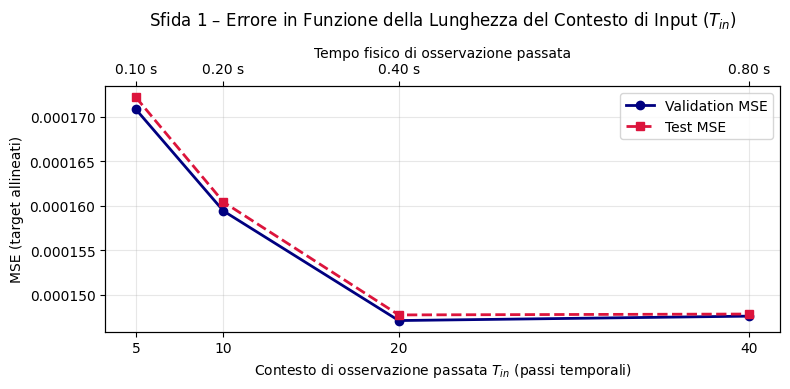

In [12]:
# =============================================================================
# Grafico Sfida 1: Curva di Scaling dell'Errore in Funzione di Tin
# =============================================================================
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(tin_df["T_in"], tin_df["val_mse"], marker="o", color="navy", lw=2, label="Validation MSE")
ax1.plot(tin_df["T_in"], tin_df["test_mse"], marker="s", color="crimson", lw=2, ls="--", label="Test MSE")
ax1.set_xlabel("Contesto di osservazione passata $T_{in}$ (passi temporali)")
ax1.set_ylabel("MSE (target allineati)")
ax1.set_xticks(tin_df["T_in"])
ax1.grid(True, alpha=0.3)

# Secondo asse con il tempo fisico
ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(tin_df["T_in"])
ax2.set_xticklabels([f"{t:.2f} s" for t in tin_df["tempo_fisico_in"]])
ax2.set_xlabel("Tempo fisico di osservazione passata")

ax1.legend(loc="upper right")
plt.title("Sfida 1 – Errore in Funzione della Lunghezza del Contesto di Input ($T_{in}$)", pad=15)
fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "challenge1_tin_scaling", subdir="03_rnn"))
plt.show()


## 8. Analisi Disaggregata Dettagliata (Variabili, Qubit e Coppie)

Valutiamo la distribuzione dell'errore predittivo per individuare eventuali bias:
1. **Magnetizzazioni (10) vs Correlazioni (45)**: confronto tra polarizzazione dei singoli qubit e interazione a due corpi.
2. **MSE per Singolo Qubit**: accuratezza sui 10 siti della catena Rydberg.
3. **Matrice di Errore delle Correlazioni $10 \times 10$**: visualizzazione spaziale dell'MSE per ciascuna coppia di atomi $(i, j)$.


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/03_rnn/disaggregated_error_analysis.jpeg


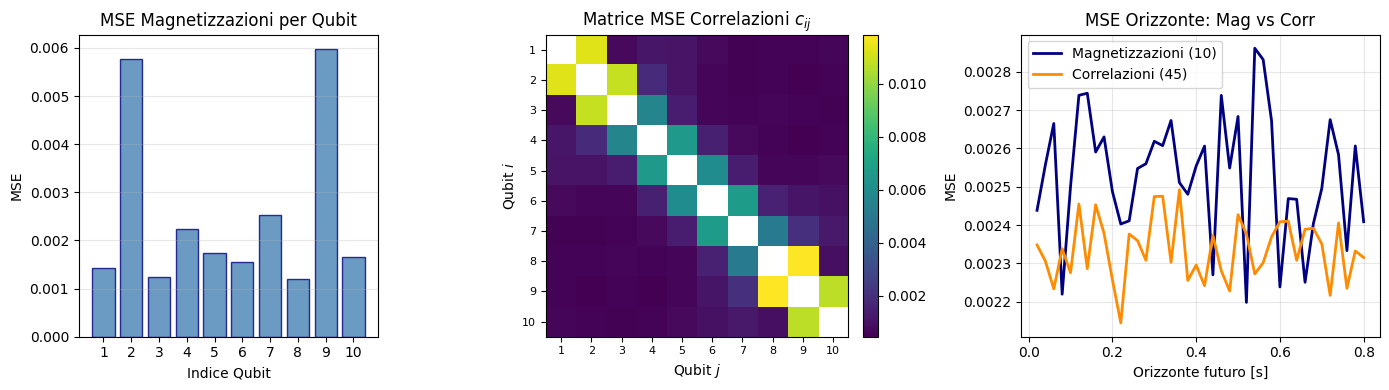

In [13]:
# =============================================================================
# 8. Analisi Disaggregata ed Esportazione Grafici
# =============================================================================
# Modello per l'analisi (M1 su finestra short)
X_va_short, Y_va_short = windows_data["short"]["val"]
Y_pred_best = predict(m1_demo, X_va_short) if "m1_demo" in locals() else Y_pred_val

# 1. Errori per qubit
qubit_errs = per_qubit_mse(Y_va_short, Y_pred_best)

# 2. Matrice correlazioni
corr_mat = corr_pair_mse_matrix(Y_va_short, Y_pred_best)

# 3. Errore temporale per gruppi
group_errs = per_horizon_group_mse(Y_va_short, Y_pred_best)

fig = plt.figure(figsize=(14, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.2, 1.2])

# Pannello A: Errore per qubit
ax0 = fig.add_subplot(gs[0])
ax0.bar(range(1, N_QUBITS + 1), qubit_errs, color="steelblue", edgecolor="navy", alpha=0.8)
ax0.set_xlabel("Indice Qubit")
ax0.set_ylabel("MSE")
ax0.set_title("MSE Magnetizzazioni per Qubit")
ax0.set_xticks(range(1, N_QUBITS + 1))
ax0.grid(True, axis="y", alpha=0.3)

# Pannello B: Heatmap correlazioni 10x10
ax1 = fig.add_subplot(gs[1])
im = ax1.imshow(corr_mat, cmap="viridis", interpolation="nearest")
ax1.set_title("Matrice MSE Correlazioni $c_{ij}$")
ax1.set_xlabel("Qubit $j$")
ax1.set_ylabel("Qubit $i$")
ax1.set_xticks(range(N_QUBITS))
ax1.set_xticklabels(range(1, N_QUBITS + 1), fontsize=8)
ax1.set_yticks(range(N_QUBITS))
ax1.set_yticklabels(range(1, N_QUBITS + 1), fontsize=8)
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)

# Pannello C: Evoluzione temporale Mag vs Corr
ax2 = fig.add_subplot(gs[2])
tt = np.arange(1, CFG["t_out"] + 1) * DT
ax2.plot(tt, group_errs["mag"], label="Magnetizzazioni (10)", color="navy", lw=2)
ax2.plot(tt, group_errs["corr"], label="Correlazioni (45)", color="darkorange", lw=2)
ax2.set_title("MSE Orizzonte: Mag vs Corr")
ax2.set_xlabel("Orizzonte futuro [s]")
ax2.set_ylabel("MSE")
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "disaggregated_error_analysis", subdir="03_rnn"))
plt.show()


## 9. Validazione di Significatività Statistica (3 Seed) e Salvataggio Checkpoint

Addestriamo la configurazione ottimale su **3 repliche con seed indipendenti (42, 43, 44)** per calcolare l'intervallo di confidenza al 95% con distribuzione $t$ di Student ($t_{0.975, 2} \approx 4.303$).
Infine salviamo il checkpoint `.keras` in `checkpoints/best_rnn_model.keras` e verifichiamo la procedura di ripristino per la sessione di inferenza finale.


In [14]:
# =============================================================================
# 9. Repliche Statistiche su 3 Seed e Salvataggio del Modello Migliore
# =============================================================================
replica_seeds = CFG["replica_seeds"]  # [42, 43, 44]
seed_mses = []
seed_maes = []
best_replica_model = None
best_replica_val = np.inf

print(f"Esecuzione repliche statistiche su seed {replica_seeds} per la configurazione vincente...")

for s in replica_seeds:
    set_seeds(s)
    rep_cfg = make_config(model=best_model_type, t_in=10, seed=s, **hp_configs[best_hp])
    rep_model = build_rnn_from_config(rep_cfg, t_in=10)

    _ = train_hybrid(
        rep_model,
        windows_data["short"]["train"][0], windows_data["short"]["train"][1],
        windows_data["short"]["val"][0], windows_data["short"]["val"][1],
        rep_cfg,
        verbose=0
    )

    val_ev = evaluate(windows_data["short"]["val"][1], predict(rep_model, windows_data["short"]["val"][0]))
    seed_mses.append(val_ev["mse"])
    seed_maes.append(val_ev["mae"])
    print(f"  Seed {s} -> Val MSE: {val_ev['mse']:.6f} | Val MAE: {val_ev['mae']:.6f}")

    if val_ev["mse"] < best_replica_val:
        best_replica_val = val_ev["mse"]
        best_replica_model = rep_model

# Calcolo intervallo di confidenza al 95% con t di Student
stats_mse = summarize(seed_mses)
stats_mae = summarize(seed_maes)

print("\n" + "=" * 60)
print(f"RISULTATO FINALE MODELLI RICORRENTI (3 Repliche Seed {replica_seeds}):")
print(f"  Validation MSE : {format_mean_ci(seed_mses, digits=6)} (95% CI Student-t)")
print(f"  Validation MAE : {format_mean_ci(seed_maes, digits=6)} (95% CI Student-t)")
print("=" * 60)

# Salvataggio del checkpoint del modello migliore
ckpt_path = PATHS["checkpoints"] / "best_rnn_model.keras"
best_replica_model.save(ckpt_path)
print(f"\nModello migliore salvato con successo in: {ckpt_path}")

# Sanity check: ricaricamento del modello salvato
loaded_model = keras.models.load_model(ckpt_path, custom_objects={"RNNSeq2Seq": RNNSeq2Seq})
re_val = evaluate(windows_data["short"]["val"][1], predict(loaded_model, windows_data["short"]["val"][0]))
assert np.isclose(re_val["mse"], best_replica_val, atol=1e-5), "Discrepanza nel modello ricaricato!"
print("Verifica ricaricamento checkpoint per inferenza finale: SUPERATA ✔")


Esecuzione repliche statistiche su seed [42, 43, 44] per la configurazione vincente...
  Seed 42 -> Val MSE: 0.000161 | Val MAE: 0.009117
  Seed 43 -> Val MSE: 0.000161 | Val MAE: 0.009140
  Seed 44 -> Val MSE: 0.000161 | Val MAE: 0.009106

RISULTATO FINALE MODELLI RICORRENTI (3 Repliche Seed [42, 43, 44]):
  Validation MSE : 0.000161 ± 0.000001 (95% CI Student-t)
  Validation MAE : 0.009121 ± 0.000043 (95% CI Student-t)

Modello migliore salvato con successo in: /content/drive/MyDrive/DL-Quantum/checkpoints/best_rnn_model.keras
Verifica ricaricamento checkpoint per inferenza finale: SUPERATA ✔


## 10. Sincronizzazione dei Risultati e Push su GitHub (Multi-Utente)

Questa cella finale rileva automaticamente l'autore attivo in base alla chiave segreta Colab (`GIT_E_TOKEN` per Ernesto -> branch `dev-ernesto`, `GIT_R_TOKEN` per Riccardo -> branch `dev-riccardo`), traccia i log numerici in `results/`, le figure esportate in `figures/`, il notebook e il codice, ed esegue il push sul branch corretto senza conflitti.


In [15]:
# =============================================================================
# Sincronizzazione dei Risultati e Push su GitHub (Multi-Utente)
# =============================================================================
import os
from pathlib import Path

target_repo = Path("/content/drive/MyDrive/DL-Quantum") if Path("/content/drive/MyDrive/DL-Quantum").exists() else REPO_PATH

print(f"--- SINCRONIZZAZIONE SUL BRANCH: {CURRENT_BRANCH} (Autore: {AUTHOR_NAME}) ---")

# 1. Configura l'identità Git dell'autore attivo
!git -C "{target_repo}" config user.name "{AUTHOR_NAME}"
!git -C "{target_repo}" config user.email "{AUTHOR_EMAIL}"

# 2. Allineamento preventivo con eventuali nuovi commit remoti (evita non-fast-forward)
!git -C "{target_repo}" fetch origin
!git -C "{target_repo}" pull --rebase --autostash origin {CURRENT_BRANCH}

# 3. Aggiunge i risultati numerici, figure, notebook e codice al tracking Git
!git -C "{target_repo}" add results/ figures/ notebooks/ src/
commit_msg = f"feat: aggiornamento risultati da Colab [{CURRENT_BRANCH}] di {AUTHOR_NAME}"
!git -C "{target_repo}" commit -m "{commit_msg}"
!git -C "{target_repo}" status -s

# 4. Push su GitHub con il token personale rilevato
if GIT_TOKEN:
    print(f"\nPush automatico in corso sul branch '{CURRENT_BRANCH}' con token di {AUTHOR_NAME}...")
    push_out = !git -C "{target_repo}" push https://{GIT_TOKEN}@github.com/Riccardo-27/DL-Quantum.git {CURRENT_BRANCH}
    print("\n".join(push_out))
    
    # Verifica esito del comando di push
    push_err = any("rejected" in l.lower() or "error:" in l.lower() or "fatal:" in l.lower() for l in push_out)
    if push_err:
        print(f"\n[ATTENZIONE] Il push è stato respinto. Risolvi eventuali divergenze con '!git -C \"{target_repo}\" pull --rebase --autostash origin {CURRENT_BRANCH}' e riprova.")
    else:
        print(f"\n✔ Sincronizzazione completata con successo su '{CURRENT_BRANCH}'!")
else:
    if IN_COLAB:
        print("\n[ATTENZIONE] Nessun token rilevato per il push automatico su Colab.")
        print("  - Se sei Ernesto: crea il segreto 'GIT_E_TOKEN' nell'icona 🔑 a sinistra.")
        print("  - Se sei Riccardo: crea il segreto 'GIT_R_TOKEN' nell'icona 🔑 a sinistra.")
    else:
        print(f"\nAmbiente locale: per il push esegui 'git push origin {CURRENT_BRANCH}' da terminale.")



--- SINCRONIZZAZIONE SUL BRANCH: dev-ernesto (Autore: Ernesto) ---
Refresh index: 100% (39/39), done.
?? figures/03_rnn/challenge1_tin_scaling.jpeg
?? figures/03_rnn/disaggregated_error_analysis.jpeg
?? figures/03_rnn/free_running_error_accumulation.jpeg
?? figures/03_rnn/loss_curves_hybrid.jpeg
?? results/results_log_ernesto.csv
[dev-ernesto d957ba0] feat(03_rnn): addestramento modelli ricorrenti e Sfida 1 [dev-ernesto] di Ernesto
 5 files changed, 17 insertions(+)
 create mode 100644 figures/03_rnn/challenge1_tin_scaling.jpeg
 create mode 100644 figures/03_rnn/disaggregated_error_analysis.jpeg
 create mode 100644 figures/03_rnn/free_running_error_accumulation.jpeg
 create mode 100644 figures/03_rnn/loss_curves_hybrid.jpeg
 create mode 100644 results/results_log_ernesto.csv

[INFO] Per abilitare il push automatico su Colab, configura il Secret 'GH_TOKEN' nell'icona 🔑 a sinistra.
